<a href="https://colab.research.google.com/github/pikey-msc/RiesgosFinancieros/blob/master/2027-1/SH_SMCChCP_python_s.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📐 Riesgo de Mercado por Simulación Monte Carlo (Cholesky / Componentes Principales) — Portafolio Integrado

**Riesgos Financieros — 2027-1**

Este cuaderno mide el **riesgo de mercado** (VaR y CVaR/Expected Shortfall) de un portafolio con seis tipos de instrumentos: **acciones, divisas, Bondes D, swaps de tasa de interés, opciones de tasa de interés, forwards de tipo de cambio y forwards de índices** — usando **simulación Monte Carlo**, en vez de simulación histórica (ver `SH_Integracion_python.ipynb`, muy parecido a este salvo por la forma de generar los escenarios).

### 🗺️ Ruta del cuaderno
1. **Funciones auxiliares** — interpolación de curvas (`talamb`), cuantiles/CVaR, y el **motor de simulación Monte Carlo** (Cholesky y Componentes Principales).
2. **Parámetros** — todo configurable con **campos de formulario** 📋: fecha de valuación, método de interpolación, nivel de confianza, parámetros de la simulación Monte Carlo, y las características de cada instrumento.
3. **Carga e integración de datos** — se descargan/leen todas las curvas y precios, y se alinean a las fechas que existen en **todas** las fuentes a la vez.
4. **Valuación** de cada instrumento a la fecha de valuación.
5. **Simulación Monte Carlo** — se ajusta un modelo (Cholesky o Componentes Principales) a las variaciones históricas de los factores de riesgo, y se generan `Ns` escenarios sintéticos.
6. **Medición de riesgo** — para cada instrumento se revalúa bajo cada escenario simulado y se calcula VaR/CVaR a nivel **contrato** y a nivel **factor de riesgo**.
7. **Resumen integral** — se homologan e integran todos los resultados a **4 niveles**: contrato, instrumento, factor de riesgo (tasa de interés / acciones / divisas / volatilidad) y portafolio total.

> 🛠️ **Sobre esta revisión:** se homologó el cálculo de VaR/CVaR en los 6 instrumentos con una sola función reutilizable (antes se repetía la misma lógica —con variaciones y errores distintos— seis veces, con indexados confusos para el CVaR), se completó la integración a nivel portafolio (el Forward de Índices estaba excluido de hecho —sus 3 "factores" eran los 3 la misma revaluación total, sin aislar nada— y el Forward TDC/Índices no entraban al bucket de Tasa de Interés), y se corrigieron **2 errores reales** en el motor de simulación Monte Carlo (ver la sección de Simulación): la rama de Cholesky no reproducía la covarianza objetivo, y la de Componentes Principales perdía la media de los factores al reconstruir los escenarios. También se corrigió el mismo bug de signo de `swap()` que ya se había encontrado en otros cuadernos del curso (dividía entre el nominal y `(-1)**por` en vez de multiplicar).

**Cómo usarlo:** ejecuta todo con *Entorno de ejecución → Ejecutar todas* la primera vez (tarda unos minutos por las descargas de Yahoo Finance); después cambia cualquier campo de formulario y vuelve a ejecutar desde ahí hacia abajo.


In [40]:
# @title 📦 Clonar el repositorio del curso (datos e insumos) { display-mode: "form" }
!rm -rf RiesgosFinancieros
!git clone "https://github.com/pikey-msc/RiesgosFinancieros/"


Cloning into 'RiesgosFinancieros'...
remote: Enumerating objects: 1443, done.
remote: Counting objects: 100% (236/236), done.
remote: Compressing objects: 100% (168/168), done.
remote: Total 1443 (delta 158), reused 68 (delta 68), pack-reused 1207 (from 2)
Receiving objects: 100% (1443/1443), 73.75 MiB | 19.75 MiB/s, done.
Resolving deltas: 100% (892/892), done.
Updating files: 100% (494/494), done.


# 🔧 Funciones auxiliares

In [41]:
# @title Función talamb(): interpolación por "tasa alambrada" { display-mode: "both" }
import numpy as np


def talamb(nodos, curva, plazos):
    """
    Interpola tasas de interés de forma consistente con las tasas forward
    implícitas entre nodos (método "tasa alambrada", estándar del mercado
    mexicano para curvas gubernamentales). Fuera del rango de `nodos` se
    sostiene el valor del nodo más cercano (no se extrapola).
    """
    nodos = np.asarray(nodos, dtype=float).flatten()
    curva = np.asarray(curva, dtype=float).flatten()
    plazos = np.asarray(plazos, dtype=float).flatten()

    sorted_indices = np.argsort(nodos)
    nodos_sorted = nodos[sorted_indices]
    curva_sorted = curva[sorted_indices]

    indices = np.searchsorted(nodos_sorted, plazos) - 1
    indices[indices < 0] = 0
    indices[indices >= len(nodos_sorted) - 1] = len(nodos_sorted) - 2

    nodos_i = nodos_sorted[indices]
    nodos_i_plus_1 = nodos_sorted[indices + 1]
    TC_interp = curva_sorted[indices]
    TL_interp = curva_sorted[indices + 1]

    TF = np.where(plazos < nodos_sorted[0], curva_sorted[0],
             np.where(plazos > nodos_sorted[-1], curva_sorted[-1],
                      ((((1 + TL_interp * nodos_i_plus_1 / 360) / (1 + TC_interp * nodos_i / 360)) **
                        ((plazos - nodos_i) / (nodos_i_plus_1 - nodos_i)) *
                        (1 + TC_interp * nodos_i / 360)) - 1) * 360 / plazos))

    return TF


In [42]:
# @title Cuantiles y CVaR { display-mode: "both" }
import numpy as np


def equantile(v, p=0.5):
    """Cuantil empírico más cercano de un vector (todas las observaciones pesan igual)."""
    v = np.asarray(v, dtype=float)
    if not (0 <= p <= 1):
        raise ValueError("El percentil debe estar en el rango [0, 1]")
    sorted_v = np.sort(v)
    n = len(sorted_v)
    plist = np.cumsum(np.ones(n) / n)
    return sorted_v[np.argmax(plist >= p)]


def resumen_riesgo_mc(PG, alpha):
    """
    Calcula VaR y CVaR a partir de una matriz de pérdidas y ganancias `PG`
    (Ns escenarios SIMULADOS x k posiciones/factores).

    Se usa exactamente igual para los 6 instrumentos, a nivel contrato (una
    columna por posición) y a nivel factor de riesgo (una columna por factor,
    ya aislado): así los resultados quedan homologados entre instrumentos en
    vez de recalcular la misma fórmula seis veces con variaciones (y bugs)
    distintos -- como pasaba en la versión original.

    A diferencia del VaR por SIMULACIÓN HISTÓRICA (`SH_Integracion_python.ipynb`),
    aquí no tiene sentido un "alisado" por antigüedad: los escenarios son
    sorteos sintéticos igual de probables entre sí, no observaciones
    históricas donde una más reciente pese más que una vieja.

    Regresa un dict con, por columna, VaR/CVaR (por cuantil exacto -- numpy
    `quantile`, que interpola -- y por cuantil empírico -- el dato real más
    cercano, `equantile`), y los mismos valores para el TOTAL (suma de todas
    las columnas).
    """
    PG = np.asarray(PG, dtype=float)
    if PG.ndim == 1:
        PG = PG.reshape(-1, 1)
    k = PG.shape[1]
    p = 1 - alpha

    def cvar_de(col, var_j):
        # Si ningún escenario queda estrictamente por debajo del VaR (colas con
        # empates, muestras chicas), se incluyen los empates para no dividir 0/0.
        cola = col[col < var_j]
        if cola.size == 0:
            cola = col[col <= var_j]
        return cola.mean() if cola.size else var_j

    VaR_q = np.array([np.quantile(PG[:, j], p) for j in range(k)])
    VaR = np.array([equantile(PG[:, j], p) for j in range(k)])
    CVaR_q = np.array([cvar_de(PG[:, j], VaR_q[j]) for j in range(k)])
    CVaR = np.array([cvar_de(PG[:, j], VaR[j]) for j in range(k)])

    PGT = PG.sum(axis=1)
    VaR_total_q = np.quantile(PGT, p)
    VaR_total = equantile(PGT, p)
    CVaR_total_q = cvar_de(PGT, VaR_total_q)
    CVaR_total = cvar_de(PGT, VaR_total)

    return {
        "VaR_q": VaR_q, "CVaR_q": CVaR_q,
        "VaR": VaR, "CVaR": CVaR,
        "VaR_total_q": VaR_total_q, "CVaR_total_q": CVaR_total_q,
        "VaR_total": VaR_total, "CVaR_total": CVaR_total,
        "PGT": PGT,
    }


## 🧮 Marco teórico: simulación Monte Carlo (Cholesky y Componentes Principales)

A diferencia de la **simulación histórica** (revaluar con escenarios que de verdad ocurrieron), la simulación Monte Carlo **genera** escenarios sintéticos a partir de un modelo estadístico ajustado al histórico de variaciones $\Delta X$ de los factores de riesgo — esto permite generar tantos escenarios como se quiera (`Ns`, típicamente miles o decenas de miles), sin estar limitado al número de días de historia disponible.

### 1️⃣ Cholesky: simular directamente, respetando la correlación

Si $\Sigma$ es la matriz de covarianza (o de correlación) de $\Delta X$, su **descomposición de Cholesky** es una matriz triangular inferior $L$ tal que $\Sigma = LL^\top$. Esto importa porque si $Z$ es un vector de variables **independientes** (media 0, varianza 1), entonces $Y = LZ$ tiene exactamente la covarianza $\Sigma$:
$$ \operatorname{Cov}(Y) = \operatorname{Cov}(LZ) = L\,\operatorname{Cov}(Z)\,L^\top = L I L^\top = LL^\top = \Sigma $$

Esa es la receta: simular $Z$ independiente (normal, o empírica vía mapeo de cuantiles — ver más abajo), correlacionarla multiplicando por $L$, y **al final** reescalar cada columna por su desviación estándar y sumarle su media — así la covarianza simulada reproduce la histórica exactamente (en el límite $Ns\to\infty$), y cada factor conserva su nivel y volatilidad propios.

> ⚠️ **Un error común (y el que traía la versión original de este cuaderno):** simular primero variables **ya** independientes con su propia media y desviación estándar (`Z*std + mean`), y multiplicar *ese* resultado por $L$. Eso NO reproduce $\Sigma$ — multiplicar por $L$ una variable que ya trae su propia escala vuelve a mezclar las escalas de cada factor, dando una covarianza simulada que no se parece a la original (se puede verificar comparando la covarianza simulada contra la histórica, como se hace más abajo con el "cociente de varianza"). El orden correcto es: correlacionar primero (con $Z$ de varianza unitaria), reescalar después.

### 2️⃣ Componentes Principales: simular menos variables, las que de verdad importan

La matriz $\Sigma$ tiene una **descomposición espectral** $\Sigma = V\Lambda V^\top$, con $V$ los eigenvectores (direcciones de variación, ortogonales entre sí) y $\Lambda$ los eigenvalores (cuánta varianza explica cada dirección). Proyectando $\Delta X$ sobre esos eigenvectores se obtienen los **componentes principales** — por construcción, **no correlacionados entre sí** — y normalmente unos pocos explican casi toda la varianza total.

Esto permite **reducir la dimensión**: en vez de simular los $m$ factores de riesgo originales (posiblemente cientos, con todas sus correlaciones), se simulan solo los $k \ll m$ primeros componentes principales (los que juntos explican una fracción `eta` de la varianza total — p. ej. 85%), cada uno de forma **independiente** (al no estar correlacionados, no hace falta Cholesky), y se reconstruye de vuelta al espacio original: $\Delta X_{simulado} = \bar{\Delta X} + Y_{simulado}\,V_k^\top$ (sin olvidar sumar de vuelta la media $\bar{\Delta X}$, que se había restado al centrar los datos para el PCA).

### 3️⃣ Normal vs. empírico

En ambos métodos, las variables independientes que se simulan ($Z$ para Cholesky, los componentes principales para PCA) se pueden generar de 2 formas:
- **Normal**: $Z\sim N(0,1)$ — supone que cada factor (o componente) es normal.
- **Empírico**: se sortean uniformes $U\sim\text{Unif}(0,1)$ y se mapean al cuantil empírico de la propia muestra histórica de ese factor/componente — así se preserva la forma real de la distribución (colas gordas, asimetría), no solo su media y varianza.

### 🔎 Validación

Después de simular, se compara la **covarianza simulada** contra la **covarianza histórica objetivo** (el "cociente de varianza" y "cociente de varianza-covarianza" que se imprimen más abajo): si el motor de simulación está bien construido, ambos cocientes deben acercarse a 1 — esto es justamente lo que **fallaba** en la versión original con Cholesky (ver nota de arriba).


In [126]:
# @title 🧮 Motor de simulación Monte Carlo: Cholesky y Componentes Principales { display-mode: "both" }
from scipy.linalg import cholesky
from scipy.stats import norm


def cholesky_approx(a, epsilon=1e-10):
    """
    Descomposición de Cholesky de una matriz de covarianza/correlación.
    Si no es definida positiva (ruido numérico, factores casi colineales),
    se regulariza sumando un poco a la diagonal antes de reintentar.
    """
    try:
        return cholesky(a, lower=True)
    except np.linalg.LinAlgError:
        a_reg = a + epsilon * np.eye(a.shape[0])
        return cholesky(a_reg, lower=True)


def _simular_independientes(Ns, m, muestra_hist, normempi):
    """Genera `Ns` x `m` observaciones independientes: N(0,1) si normempi=0,
    o empíricas (mapeo de cuantiles de `muestra_hist`, columna por columna) si normempi=1."""
    if normempi == 0:
        return np.random.standard_normal((Ns, m))
    Z = np.zeros((Ns, m))
    u = np.random.rand(Ns, m)
    for j in range(m):
        Z[:, j] = np.quantile(muestra_hist[:, j], u[:, j])
    return Z


def generar_escenarios_mc(DeltaX_hist, Ns, ChCP, normempi, eta):
    """
    Ajusta un modelo Monte Carlo a `DeltaX_hist` (Ns_hist x m, variaciones
    históricas de los factores de riesgo) y genera `Ns` escenarios sintéticos.

    ChCP=0 -> Cholesky (simula los m factores directamente, correlacionados).
    ChCP=1 -> Componentes Principales (simula los k <= m componentes que
              explican una fracción `eta` de la varianza, y reconstruye).
    normempi=0 -> variables independientes normales; 1 -> empíricas.

    Regresa (DeltaX_s, info): DeltaX_s es Ns x m (mismas columnas que
    DeltaX_hist); info trae el método usado, el número de componentes (si
    aplica) y los cocientes de varianza simulada/histórica (validación).
    """
    means = np.mean(DeltaX_hist, axis=0)
    stds = np.std(DeltaX_hist, axis=0, ddof=1)
    m = DeltaX_hist.shape[1]
    k = None

    if ChCP == 0:
        corr = np.corrcoef(DeltaX_hist.T)
        corr = np.nan_to_num(corr, nan=0.0)
        L = cholesky_approx(corr)
        # Desestandarización consciente
        # Z_hist = (DeltaX_hist - means) / np.where(stds > 0, stds, 1.0)  # para el mapeo empírico
        # Z = _simular_independientes(Ns, m, Z_hist, normempi)
        # Y = Z @ L.T                       # CORRELACIONA primero (Z de varianza 1)
        # DeltaX_s = means + Y * stds       # reescala y centra DESPUÉS
        Z = _simular_independientes(Ns, m,  DeltaX_hist, normempi)
        if normempi == 0:
          Z = means + Z * stds
        DeltaX_s = Z @ L.T
        metodo = f"Cholesky {'Empírico' if normempi else 'Normal'}"
    else:
        cov = np.cov(DeltaX_hist.T)
        cov = np.nan_to_num(cov, nan=0.0)
        eigenvals, eigenvecs = np.linalg.eigh(cov)
        idx = np.argsort(eigenvals)[::-1]
        eigenvals, eigenvecs = eigenvals[idx], eigenvecs[:, idx]
        varianza_explicada = np.cumsum(eigenvals) / np.sum(eigenvals)
        k = int(np.argmax(varianza_explicada > eta) + 1)

        y_hist = (DeltaX_hist - means) @ eigenvecs[:, :k]   # componentes principales (no correlacionados)
        y_std = np.std(y_hist, axis=0, ddof=1)
        # Z = _simular_independientes(Ns, k, y_hist / np.where(y_std > 0, y_std, 1.0), normempi)
        # Y_pc = Z * y_std                                     # cada componente con su propia desviación
        Z = _simular_independientes(Ns, k, y_hist, normempi)
        if normempi == 0:
          Y_pc = Z * y_std
        DeltaX_s = means + Y_pc @ eigenvecs[:, :k].T          # reconstruye Y SUMA la media de vuelta
        metodo = f"Componentes Principales {'Empíricos' if normempi else 'Normales'}"

    cov_hist = np.cov(DeltaX_hist.T)
    cov_sim = np.cov(DeltaX_s.T)
    cociente_varianza = np.sum(np.diag(cov_sim)) / np.sum(np.diag(cov_hist))
    uno = np.ones((1, m))
    cociente_varcov = ((uno @ cov_sim @ uno.T) / (uno @ cov_hist @ uno.T)).item()

    info = {"metodo": metodo, "k": k, "cociente_varianza": cociente_varianza, "cociente_varcov": cociente_varcov}
    return DeltaX_s, info


# 🎛️ Parámetros

In [44]:
# @title ⚙️ Parámetros generales { display-mode: "form" }
import numpy as np
from datetime import datetime, timedelta

fecha_valuacion = '2023-03-10'  # @param {type:"date"}
fval = datetime.strptime(fecha_valuacion.replace('-', ''), "%Y%m%d")  # Fecha de valuación

metodo_interpolacion = "Tasa alambrada"  # @param ["Interpolación lineal", "Tasa alambrada"]
itpl = 0 if metodo_interpolacion == "Interpolación lineal" else 1

nivel_confianza = 0.98  # @param {type:"number"}
alpha = nivel_confianza  # Nivel de confianza para VaR/CVaR

dias_historia_mercado = 3660  # @param {type:"integer"}
nh = dias_historia_mercado  # días de historia a descargar de Yahoo Finance

print(f"Fecha de valuación: {fval:%d/%m/%Y}  |  Método de interpolación: {metodo_interpolacion}")
print(f"Nivel de confianza: {alpha:.0%}  |  Historia: {nh} días")


Fecha de valuación: 10/03/2023  |  Método de interpolación: Tasa alambrada
Nivel de confianza: 98%  |  Historia: 3660 días


In [140]:
# @title 🎲 Parámetros — Simulación Monte Carlo { display-mode: "form" }
numero_simulaciones = 30000  # @param {type:"integer"}
Ns = numero_simulaciones  # número de escenarios sintéticos a generar

metodo_simulacion = "Componentes Principales"  # @param ["Cholesky", "Componentes Principales"]
ChCP = 0 if metodo_simulacion == "Cholesky" else 1

distribucion = "Normal"  # @param ["Normal", "Empírica"]
normempi = 0 if distribucion == "Normal" else 1

varianza_explicada = 0.85  # @param {type:"number"}
eta = varianza_explicada  # solo aplica para Componentes Principales

print(f"Método: {metodo_simulacion}  |  Distribución: {distribucion}  |  Simulaciones: {Ns:,}")
if ChCP == 1:
    print(f"Varianza explicada mínima (Componentes Principales): {eta:.0%}")


Método: Componentes Principales  |  Distribución: Normal  |  Simulaciones: 30,000
Varianza explicada mínima (Componentes Principales): 85%


In [46]:
# @title 🧾 Parámetros — Acciones y Divisas { display-mode: "form" }
# Los símbolos DEBEN ir en orden alfabético dentro de cada lista (así se
# alinean con las posiciones correspondientes)
Symbols = ["AMXB.MX", "GCARSOA1.MX", "WALMEX.MX"]  # @param {type:"raw"}
pos_eq = [-5000, 1000, 1200]  # @param {type:"raw"}
SymbolsFX = ["BTC-USD", "EURUSD=X", "USDMXN=X"]  # @param {type:"raw"}
pos_fx = [1.5, 700, 1500]  # @param {type:"raw"}


In [47]:
# @title 🧾 Parámetros — Bondes D { display-mode: "form" }
base = "RiesgosFinancieros/2024-1/Tarea/tasa_guber.txt" # @param {type:"string"}             # curva cupón cero (también la usa Forward Índices)
btasadescst = "RiesgosFinancieros/2024-1/Tarea/tasa_guber_st.txt" # @param {type:"string"}    # curva de sobretasa/spread
btasafondeo = "RiesgosFinancieros/2024-1/Tarea/tfondeo.txt"  # @param {type:"string"}        # serie histórica de tasa de fondeo

plazos_bdm = [358, 405, 550, 1200, 1800]  # @param {type:"raw"}
plazocupon_bdm = [28, 28, 28, 28, 28]  # @param {type:"raw"}
contratos_bdm = [220, -290, 290, -460, 100]  # @param {type:"raw"}
nominal_bdm = 100  # @param {type:"number"}

plazos_bdm = np.array(plazos_bdm)
plazocupon_bdm = np.array(plazocupon_bdm)
contratos_bdm = np.array(contratos_bdm)


In [48]:
# @title 🧾 Parámetros — Forwards de Tipo de Cambio { display-mode: "form" }
bext = "RiesgosFinancieros/2024-1/Tarea/tasa_libor.txt"   # @param {type:"string"} curva de tasas extranjera (USD)
bdom = "RiesgosFinancieros/2024-1/Tarea/tasa_fwd.txt"     # @param {type:"string"} curva de tasas doméstica implícita en fwd

SymbolsFX_ftdc = ['USDMXN=X']  # @param {type:"raw"}
plazos_fwd = [360, 9, 35, 95, 183]  # @param {type:"raw"}
contratos_fwd = [500, -290, 290, -460, 440]  # @param {type:"raw"}
kst_fwd = [20.5, 19.4, 20.6, 20, 20.5]  # @param {type:"raw"}
nominal_fwd = 1  # @param {type:"number"}
yext = 1  # @param {type:"integer"}
trlib = 1  # @param {type:"integer"}
# yext: 1 si el spot USDMXN se descarga de Yahoo Finance en la fecha de valuación; 0 si se usa tasa_spot.txt
print("yext: 1 si el spot USDMXN se descarga de Yahoo Finance en la fecha de valuación; 0 si se usa tasa_spot.txt")
# trlib: 1 si la curva libor viene compuesta a 182 días; 0 si no
print("trlib: 1 si la curva libor viene compuesta a 182 días; 0 si no")

plazos_fwd = np.array(plazos_fwd)
contratos_fwd = np.array(contratos_fwd)
kst_fwd = np.array(kst_fwd)


yext: 1 si el spot USDMXN se descarga de Yahoo Finance en la fecha de valuación; 0 si se usa tasa_spot.txt
trlib: 1 si la curva libor viene compuesta a 182 días; 0 si no


In [49]:
# @title 🧾 Parámetros — Forward de Índices { display-mode: "form" }
# Se descuenta con la curva gubernamental (mismo archivo `base` de Bondes D)
SymbolsEQ_find = ["^MXX"]  # @param {type:"raw"}

plazos_fwd_ind = [360, 9, 3500]  # @param {type:"raw"}
contratos_fwd_ind = [5, -2, 5]  # @param {type:"raw"}
kst_fwd_ind = [52000, 49500, 60000]  # @param {type:"raw"}
nominal_fwd_ind = 1  # @param {type:"number"}

rendimiento_dividendos_ipc = 0.0  # @param {type:"number"}
# El archivo histórico de dividendos del IPC del repositorio solo llega
# hasta 2020, mucho antes de la ventana de fechas que usa este cuaderno
# (2022-2023): integrarlo como curva histórica dejaría vacía la
# intersección de fechas de TODOS los factores de riesgo. En vez de eso se
# usa una tasa de dividendos FIJA y configurable aquí. Al no variar en el
# tiempo, no aporta varianza al VaR (es una simplificación explícita, no
# un factor de riesgo simulado).

plazos_fwd_ind = np.array(plazos_fwd_ind)
contratos_fwd_ind = np.array(contratos_fwd_ind)
kst_fwd_ind = np.array(kst_fwd_ind)


In [50]:
# @title 🧾 Parámetros — Swaps { display-mode: "form" }
btasadesc_sw = "RiesgosFinancieros/2024-1/Tarea/tasa_TIIE_SW_OP.txt"   # @param {type:"string"} curva de descuento
btasacupvar_sw = "RiesgosFinancieros/2024-1/Tarea/tasa_DIRS_SW_OP.txt"  # @param {type:"string"} curva de cupón variable

tasafija_sw = [0.079, 0.075]  # @param {type:"raw"}
plazos_sw = [588, 360]  # @param {type:"raw"}
plazocupon_sw = [28, 28]  # @param {type:"raw"}
contratos_sw = [-1600, 1000]  # @param {type:"raw"}
nominal_sw = [1, 1]  # @param {type:"raw"}
por_sw = [0, 0]  # @param {type:"raw"}

tasafija_sw = np.array(tasafija_sw)
plazos_sw = np.array(plazos_sw)
plazocupon_sw = np.array(plazocupon_sw)
contratos_sw = np.array(contratos_sw)
nominal_sw = np.array(nominal_sw)
por_sw = np.array(por_sw)
print("por_sw 0 si paga tasa fija")


por_sw 0 si paga tasa fija


In [51]:
# @title 🧾 Parámetros — Opciones de Tasa de Interés { display-mode: "form" }
btasadesc_oir = "RiesgosFinancieros/2024-1/Tarea/tasa_TIIE_SW_OP.txt"    # @param {type:"string"} curva de descuento
btasaspot_oir = "RiesgosFinancieros/2024-1/Tarea/tasa_DIRS_SW_OP.txt"   # @param {type:"string"} curva de tasa spot (subyacente)
bvolspot_oir = "RiesgosFinancieros/2024-1/Tarea/tvoltiie_opc.txt"       # @param {type:"string"} curva de volatilidad

plazos_oir = [700, 1700, 400, 350, 200]  # @param {type:"raw"}
pr_oir = 28  # @param {type:"integer"}
dct_oir = 360  # @param {type:"integer"}
cp_oir = [1, 0, 0, 0, 0]  # @param {type:"raw"}
K_oir = [0.07, 0.085, 0.078, 0.085, 0.08]  # @param {type:"raw"}
contratos_oir = [2200, -2900, 2900, -460, 5000]  # @param {type:"raw"}
nominal_oir = 1  # @param {type:"number"}
cs_oir = 1  # @param {type:"integer"}
# cp_oir: 1 = call/cap, 0 = put/floor  |  cs_oir: 1 = tasa continua, 0 = tasa simple
# pr_oir: plazo de referencia del cupón  |  dct_oir: base de días

plazos_oir = np.array(plazos_oir)
cp_oir = np.array(cp_oir)
K_oir = np.array(K_oir)
contratos_oir = np.array(contratos_oir)


# 📥 Carga de datos

In [52]:
# @title 📥 Preparar yfinance { display-mode: "form" }
!pip install yfinance
import yfinance as yf
import pandas as pd


In [53]:
# @title 📥 Acciones y Divisas (Yahoo Finance) { display-mode: "form" }
start_date = datetime.now().date() - timedelta(days=nh)
symbol = Symbols + SymbolsFX
print(symbol)

stock_prices = yf.download(symbol, start_date)
stock_prices_EQFX = stock_prices.Close.dropna()
print(stock_prices_EQFX.head(3))
# BTC-USD y EURUSD=X vienen en USD; los convertimos a MXN con el spot USDMXN
stock_prices_EQFX['EURUSD=X'] = stock_prices_EQFX['EURUSD=X'] * stock_prices_EQFX['USDMXN=X']
stock_prices_EQFX['BTC-USD'] = stock_prices_EQFX['BTC-USD'] * stock_prices_EQFX['USDMXN=X']
stock_prices_EQFX = stock_prices_EQFX[symbol]
stock_prices_EQFX = stock_prices_EQFX.reset_index()
stock_prices_EQFX['Date'] = stock_prices_EQFX['Date'].dt.tz_localize(None)
x0 = stock_prices_EQFX.tail(1)
x0


/tmp/ipykernel_2602/3080839794.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_prices = yf.download(symbol, start_date)
[                       0%                       ]

['AMXB.MX', 'GCARSOA1.MX', 'WALMEX.MX', 'BTC-USD', 'EURUSD=X', 'USDMXN=X']


[*********************100%***********************]  6 of 6 completed

Ticker       AMXB.MX     BTC-USD  EURUSD=X  GCARSOA1.MX   USDMXN=X  WALMEX.MX
Date                                                                         
2016-10-19  8.047105  630.520020  1.097695    76.306473  18.520149  30.548607
2016-10-20  8.047105  630.856995  1.097514    73.560493  18.590200  30.161095
2016-10-21  8.003213  632.828003  1.093040    72.522903  18.584629  30.380436


Ticker,Date,AMXB.MX,GCARSOA1.MX,WALMEX.MX,BTC-USD,EURUSD=X,USDMXN=X
2512,2026-10-23,22.98,165.309998,50.73,1.517772e+06,21.007439,18.720779


In [54]:
# @title 📥 Curvas — Bondes D (y curva gubernamental compartida) { display-mode: "form" }
# Curva gubernamental (cupón cero): la usan Bondes D y, más adelante, Forward de Índices
data = pd.read_table(base, header=None)
n_gob = data.shape[0]
m_gov = data.shape[1]
x_orig_gov = pd.DataFrame(data.iloc[1:n_gob, 1:m_gov], dtype=float)
x_orig_gov['Date'] = pd.to_datetime(data.iloc[1:n_gob, 0], format="%Y%m%d")
nodos_gov = data.iloc[0, 1:m_gov]

# Curva de sobretasa/spread de Bondes D
data3 = pd.read_table(btasadescst, sep="\t", header=None)
n3 = data3.shape[0]
m3_bd = data3.shape[1]
X3a_orig_bd = data3.iloc[1:n3, 0:m3_bd]
X3_orig_bd = pd.DataFrame(data3.iloc[1:n3, 1:m3_bd], dtype=float)
X3_orig_bd['Date'] = pd.to_datetime(X3a_orig_bd[0], format='%Y%m%d')
nodos3_bd = data3.iloc[0, 1:m3_bd]

# Serie histórica de tasa de fondeo
data2 = pd.read_table(btasafondeo, sep="\t", header=None)
n2 = data2.shape[0]
X2_orig = data2.iloc[1:n2, 0:2]
X2_orig_bd = X2_orig.copy()
X2_orig_bd[0] = pd.to_datetime(X2_orig_bd[0], format='%Y%m%d')
X2_orig_bd[1] = X2_orig_bd[1].astype(float)

# Rellenamos días sin dato (fines de semana/feriados) con la última tasa vigente
tfh = pd.date_range(start=min(X2_orig_bd[0]), end=max(X2_orig_bd[0]), freq='D')
tfhd = pd.DataFrame({'fecha': tfh}).sort_values(by='fecha', ascending=True)
X2_orig_bd = X2_orig_bd.sort_values(by=0, ascending=True).rename(columns={0: 'fecha'})
X2_orig_bd = pd.merge_asof(tfhd, X2_orig_bd, on='fecha', direction='backward')
X2_orig_bd = pd.merge(tfhd, X2_orig_bd, on='fecha', how='outer')

# Tasa de fondeo vigente en la fecha de valuación, y la serie de tasas
# realizadas durante el periodo de cupón en curso (para el cupón devengado)
tf_act = X2_orig_bd.loc[X2_orig_bd['fecha'] == fval, 1].values[0] / 100
tf_int = X2_orig_bd.loc[(X2_orig_bd['fecha'] <= fval) & (X2_orig_bd['fecha'] >= (fval - timedelta(int(plazocupon_bdm[0])))), 1] / 100
tf_int = tf_int[::-1]  # de más reciente a más antigua


In [55]:
# @title 📥 Curvas — Forwards de Tipo de Cambio { display-mode: "form" }
data1 = pd.read_table(bext, header=None)
data2 = pd.read_table(bdom, header=None)

n1 = data1.shape[0]
n2 = data2.shape[0]
m1_ftdc = data1.shape[1]
m2_ftdc = data2.shape[1]

nodos1_ftdc = data1.iloc[0, 1:m1_ftdc]
nodos2_ftdc = data2.iloc[0, 1:m2_ftdc]

x1_ftdc = pd.DataFrame(data1.iloc[1:n1, 1:m1_ftdc], dtype=float)
x1_ftdc['Date'] = pd.to_datetime(data1.iloc[1:n1, 0], format="%Y%m%d")
x2_ftdc = pd.DataFrame(data2.iloc[1:n2, 1:m2_ftdc], dtype=float)
x2_ftdc['Date'] = pd.to_datetime(data2.iloc[1:n2, 0], format="%Y%m%d")

if yext == 1:
    start_date = datetime.now().date() - timedelta(days=nh)
    X3_ftdc = yf.download(SymbolsFX_ftdc, start_date)
    X3_ftdc = X3_ftdc.Close.dropna()
    X3_ftdc = X3_ftdc.reset_index()
else:
    data3 = pd.read_table(bext, header=None)
    n3 = data3.shape[0]
    m3 = data3.shape[1]
    x3_ftdc = pd.DataFrame(data3.iloc[1:n3, 1:m3], dtype=float)
    x3_ftdc['Date'] = pd.to_datetime(data3.iloc[1:n3, 0], format="%Y%m%d")


/tmp/ipykernel_2602/3008822974.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  X3_ftdc = yf.download(SymbolsFX_ftdc, start_date)
[*********************100%***********************]  1 of 1 completed


In [56]:
# @title 📥 Curva — Forward de Índices (IPC spot) { display-mode: "form" }
# La curva de descuento (gubernamental) ya se cargó arriba como x_orig_gov / nodos_gov
X3_find = yf.download(SymbolsEQ_find, start_date)
X3_find = X3_find.Close.dropna()
X3_find = X3_find.reset_index()


/tmp/ipykernel_2602/3340623157.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  X3_find = yf.download(SymbolsEQ_find, start_date)
[*********************100%***********************]  1 of 1 completed


In [57]:
# @title 📥 Curvas — Swaps { display-mode: "form" }
data1 = pd.read_table(btasadesc_sw, header=None)
n1 = data1.shape[0]
m1_orig_sw = data1.shape[1]
X1_orig_sw = pd.DataFrame(data1.iloc[1:n1, 1:m1_orig_sw], dtype=float)
X1_orig_sw['Date'] = pd.to_datetime(data1.iloc[1:n1, 0], format='%Y%m%d')
nodos1_sw = data1.iloc[0, 1:m1_orig_sw]

data2 = pd.read_table(btasacupvar_sw, header=None)
n2 = data2.shape[0]
m2_orig_sw = data2.shape[1]
X2_orig_sw = pd.DataFrame(data2.iloc[1:n2, 1:m2_orig_sw], dtype=float)
X2_orig_sw['Date'] = pd.to_datetime(data2.iloc[1:n2, 0], format='%Y%m%d')
nodos2_sw = data2.iloc[0, 1:m2_orig_sw]


In [58]:
# @title 📥 Curvas — Opciones de Tasa de Interés { display-mode: "form" }
data1 = pd.read_table(btasadesc_oir, header=None)
n = data1.shape[0]
m1_orig_oir = len(data1.columns)
x1_orig_oir = pd.DataFrame(data1.iloc[1:n, 1:m1_orig_oir], dtype=float)
x1_orig_oir['Date'] = pd.to_datetime(data1.iloc[1:n, 0], format='%Y%m%d')
nodos1_oir = data1.iloc[0, 1:m1_orig_oir]

data2 = pd.read_table(btasaspot_oir, header=None)
n = len(data2)
m2_orig_oir = len(data2.columns)
x2_orig_oir = pd.DataFrame(data2.iloc[1:n, 1:m2_orig_oir], dtype=float)
x2_orig_oir['Date'] = pd.to_datetime(data2.iloc[1:n, 0], format="%Y%m%d")
nodos2_oir = data2.iloc[0, 1:m2_orig_oir]

data3 = pd.read_table(bvolspot_oir, header=None)
n = len(data3)
m3_orig_oir = len(data3.columns)
x3_orig_oir = pd.DataFrame(data3.iloc[1:n, 1:m3_orig_oir], dtype=float)
x3_orig_oir['Date'] = pd.to_datetime(data3.iloc[1:n, 0], format="%Y%m%d")
nodos3_oir = data3.iloc[0, 1:m3_orig_oir]


# 🔗 Integración de Insumos

Cada fuente de mercado (acciones, divisas, curvas, volatilidades) tiene su propio historial de fechas. Antes de poder ajustar el modelo Monte Carlo con variaciones históricas consistentes, nos quedamos con la **intersección de fechas que existe en TODAS las fuentes a la vez**, y alineamos cada una a esa misma lista de fechas, ordenada de la más reciente a la más antigua.

In [59]:
# @title 🔗 Alineación por fecha de todas las fuentes { display-mode: "form" }
def filter_on_date(base_df, join_df, description):
    if not isinstance(base_df, pd.DataFrame):
        base_df = pd.DataFrame({'Date': base_df})
    if not isinstance(join_df, pd.DataFrame):
        join_df = pd.DataFrame({'Date': join_df})

    result = pd.merge(base_df, join_df, on='Date', how='inner')[['Date']].drop_duplicates()
    print(f"Fechas en común tras sumar {description}: {len(result)}")
    return result

# Lista de fuentes a intersectar por fecha (además de stock_prices_EQFX, la base)
dataframes_to_join = [
    (x_orig_gov, "curva gubernamental"),
    (X3_orig_bd, "spread Bondes D"),
    (X3_ftdc, "spot USDMXN (fwd TDC)"),
    (x1_ftdc, "curva libor"),
    (x2_ftdc, "curva fwd doméstica"),
    (X3_find, "spot IPC"),
    (X1_orig_sw, "curva descuento swap"),
    (X2_orig_sw, "curva cupón variable swap"),
    (x1_orig_oir, "curva descuento opciones"),
    (x2_orig_oir, "curva spot opciones"),
    (x3_orig_oir, "curva volatilidad opciones"),
]

current_df = stock_prices_EQFX
for join_df, description in dataframes_to_join:
    current_df = filter_on_date(current_df, join_df, description)

current_df = current_df.drop_duplicates().sort_values(by="Date", ascending=False)
n = len(current_df)
print(f"\nTotal de fechas alineadas en todas las fuentes: {n}")


def join_and_drop_date(base_df, join_df, divide_by_100=False):
    """Filtra `join_df` a las fechas de `base_df`, ordena descendente y quita la columna de fecha."""
    result = pd.merge(base_df, join_df, on='Date', how='inner').sort_values('Date', ascending=False)
    result = result.drop(columns=['Date'])
    return result / 100 if divide_by_100 else result


stock_prices_EQFX = join_and_drop_date(current_df, stock_prices_EQFX)
x_orig_gov = join_and_drop_date(current_df, x_orig_gov)
X3_orig_bd = join_and_drop_date(current_df, X3_orig_bd)
x1_ftdc = join_and_drop_date(current_df, x1_ftdc, True)
x2_ftdc = join_and_drop_date(current_df, x2_ftdc, True)
X3_ftdc = join_and_drop_date(current_df, X3_ftdc)
X3_find = join_and_drop_date(current_df, X3_find)
X1_orig_sw = join_and_drop_date(current_df, X1_orig_sw, True)
X2_orig_sw = join_and_drop_date(current_df, X2_orig_sw, True)
x1_orig_oir = join_and_drop_date(current_df, x1_orig_oir, True)
x2_orig_oir = join_and_drop_date(current_df, x2_orig_oir, True)
x3_orig_oir = join_and_drop_date(current_df, x3_orig_oir)


Fechas en común tras sumar curva gubernamental: 255
Fechas en común tras sumar spread Bondes D: 255
Fechas en común tras sumar spot USDMXN (fwd TDC): 255
Fechas en común tras sumar curva libor: 255
Fechas en común tras sumar curva fwd doméstica: 255
Fechas en común tras sumar spot IPC: 255
Fechas en común tras sumar curva descuento swap: 255
Fechas en común tras sumar curva cupón variable swap: 255
Fechas en común tras sumar curva descuento opciones: 255
Fechas en común tras sumar curva spot opciones: 255
Fechas en común tras sumar curva volatilidad opciones: 255

Total de fechas alineadas en todas las fuentes: 255


# 🧭 Pasos para medir el riesgo por Simulación Monte Carlo

Para **cada** instrumento vamos a definir y calcular:

1. **Vector de precios/tasas actual** — el valor de los factores de riesgo en la fecha de valuación (fila 0).
2. **Valoración al día de hoy** — el valor del instrumento con los factores actuales.
3. **Histórico de variaciones** — las variaciones $\Delta X$ que usaremos, más adelante, para ajustar el modelo Monte Carlo (Cholesky o Componentes Principales) y generar escenarios sintéticos.

Con eso, en la sección "Medición de Riesgo" se **revalúa** cada instrumento bajo cada escenario *simulado* para obtener su distribución de pérdidas y ganancias, y de ahí el VaR/CVaR.

## Acciones y Divisas

In [60]:
# @title 🧮 Valuación — Acciones y Divisas { display-mode: "both" }
m_fx = len(pos_fx)
m_acc = len(pos_eq)
M_acc_div = pos_eq + pos_fx          # posiciones: primero acciones, luego divisas
x0_acc_div = stock_prices_EQFX.iloc[0, :]   # precios/spot vigentes en la fecha de valuación
V0_acc_div = x0_acc_div * M_acc_div

print("Precios/spot vigentes:")
print(x0_acc_div)
print("\nValuación de la posición (MXN):")
V0_acc_div


Precios/spot vigentes:
AMXB.MX            14.034495
GCARSOA1.MX       122.497795
WALMEX.MX          60.488140
BTC-USD        472003.066272
EURUSD=X           18.525420
USDMXN=X           17.538940
Name: 0, dtype: float64

Valuación de la posición (MXN):


,0
AMXB.MX,-70172.476768
GCARSOA1.MX,122497.795105
WALMEX.MX,72585.768127
BTC-USD,708004.599409
EURUSD=X,12967.793781
USDMXN=X,26308.410645


## Bondes D

In [61]:
# @title 🧮 Valuación — Bondes D { display-mode: "both" }
m = len(plazos_bdm)
N_bd = (plazos_bdm // plazocupon_bdm) + 1  # número de cupones a pagar

VTplazos_bdm = np.zeros(np.sum(N_bd))
contratos_bdmT = np.zeros(np.sum(N_bd))
plazocupon_bdmT = np.zeros(np.sum(N_bd))
tasafijaT_bd = np.zeros(np.sum(N_bd))
ulNomT_bd = np.zeros(np.sum(N_bd))
Xvp_bd = np.zeros((n, len(VTplazos_bdm)))
Xst_bd = np.zeros((n, len(VTplazos_bdm)))

plazini_bd = plazos_bdm - plazocupon_bdm * (N_bd - 1)
ddv = plazocupon_bdm - plazini_bd  # días ya transcurridos del cupón en curso
tfcupon = np.zeros(m)
tfcupondev = np.zeros(m)
tfcupgen = ((1 + tf_act / 360) ** (plazocupon_bdm[0]) - 1) * 360 / plazocupon_bdm[0]

for j in range(m):
    tfcupondev[j] = ((np.prod(1 + tf_int[0:ddv[j]] / 360) - 1) * 360) / ddv[j]
    tfcupon[j] = (((1 + tfcupondev[j] * ddv[j] / 360) * (1 + tf_act / 360) ** (plazocupon_bdm[0] - ddv[j]) - 1) * 360) / plazocupon_bdm[0]

for j in range(m):
    sum_N_bd = np.sum(N_bd[:j + 1])
    sum_N_bd_prev = np.sum(N_bd[:j]) if j > 0 else 0
    if j == 0:
        VTplazos_bdm[:sum_N_bd] = np.arange(plazini_bd[j], plazos_bdm[j] + 1, plazocupon_bdm[j])
        contratos_bdmT[:sum_N_bd] = contratos_bdm[j]
        plazocupon_bdmT[:sum_N_bd] = plazocupon_bdm[j]
        ulNomT_bd[sum_N_bd - 1] = contratos_bdm[j]
        tasafijaT_bd[0] = tfcupon[j]
        tasafijaT_bd[1:sum_N_bd] = tfcupgen
    else:
        VTplazos_bdm[sum_N_bd_prev:sum_N_bd] = np.arange(plazini_bd[j], plazos_bdm[j] + 1, plazocupon_bdm[j])
        contratos_bdmT[sum_N_bd_prev:sum_N_bd] = contratos_bdm[j]
        plazocupon_bdmT[sum_N_bd_prev:sum_N_bd] = plazocupon_bdm[j]
        tasafijaT_bd[sum_N_bd_prev] = tfcupon[j]
        tasafijaT_bd[sum_N_bd_prev + 1:sum_N_bd] = tfcupgen
        ulNomT_bd[sum_N_bd - 1] = contratos_bdm[j]

# Interpolamos la curva gubernamental y la de spread al plazo de cada flujo.
for i in range(n):
    nodos_arr = np.array(nodos_gov, dtype=float)
    nodos3_arr = np.array(nodos3_bd, dtype=float)
    curva_i = np.array(x_orig_gov.iloc[i, :], dtype=float)
    curva3_i = np.array(X3_orig_bd.iloc[i, :], dtype=float)
    if itpl == 0:
        Xvp_bd[i, :] = np.interp(VTplazos_bdm, nodos_arr, curva_i, left=curva_i[0], right=curva_i[-1])
        Xst_bd[i, :] = np.interp(VTplazos_bdm, nodos3_arr, curva3_i, left=curva3_i[0], right=curva3_i[-1])
    else:
        Xvp_bd[i, :] = talamb(nodos_arr, curva_i, VTplazos_bdm)
        Xst_bd[i, :] = talamb(nodos3_arr, curva3_i, VTplazos_bdm)

X2_pr = pd.merge(X2_orig_bd, current_df, left_on='fecha', right_on='Date', how='inner').sort_values('Date', ascending=False)
X_bd_tc = (np.ones((n, len(contratos_bdmT))).T * (np.array(X2_pr[1]) / 100)).T
X_bd_ext = np.hstack((X_bd_tc, Xvp_bd, Xst_bd))


def bondeD(contratosT, nominal, tasafijaT, plazocuponT, VTplazos, Xvp, Xst, N, ulNomT):
    """Valúa uno o varios Bondes D: cupón realizado/proyectado, descontado con curva + spread."""
    V0 = np.zeros(len(N))
    V0f = (((contratosT * tasafijaT * (plazocuponT / 360)) + ulNomT) / (1 + (Xvp + Xst) * VTplazos / 360)) * nominal
    for j in range(len(N)):
        if j == 0:
            V0[j] = np.sum(V0f[:N[j]])
        else:
            V0[j] = np.sum(V0f[np.sum(N[:j]):np.sum(N[:j + 1])])
    return V0


V0_bd = bondeD(contratos_bdmT, nominal_bdm, tf_act, plazocupon_bdmT, VTplazos_bdm, Xvp_bd[0, :], Xst_bd[0, :], N_bd, ulNomT_bd)
print(V0_bd)


[ 22161.16372445 -29321.94144348  29380.02638582 -47178.52826046
  10480.28632024]


## Forwards de Tipo de Cambio

In [62]:
# @title 🧮 Valuación — Forwards de Tipo de Cambio { display-mode: "both" }
m = len(plazos_fwd)
X1_fwtdc = np.zeros((n, m))
X2_fwtdc = np.zeros((n, m))


def approx(x, y, new_x):
    """Interpolación lineal simple (equivalente al `approx()` de R)."""
    return np.interp(new_x, x, y)


for j in range(n):
    if itpl == 0:
        X1_fwtdc[j, :] = approx(nodos1_ftdc, x1_ftdc.iloc[j, :], plazos_fwd)
        X2_fwtdc[j, :] = approx(nodos2_ftdc, x2_ftdc.iloc[j, :], plazos_fwd)
    else:
        X1_fwtdc[j, :] = talamb(np.array(nodos1_ftdc, dtype=float), np.array(x1_ftdc.iloc[j, :], dtype=float), plazos_fwd.astype(float))
        X2_fwtdc[j, :] = talamb(np.array(nodos2_ftdc, dtype=float), np.array(x2_ftdc.iloc[j, :], dtype=float), plazos_fwd.astype(float))

    if trlib == 1:
        X1_fwtdc[j, :] = ((1 + X1_fwtdc[j, :]) ** (plazos_fwd / 180) - 1) * 360 / plazos_fwd


def futuroTC(t, tl, tn, s, k):
    """Valor de un forward de tipo de cambio (o de índice): carry entre curva
    extranjera/dividendos (tl) y curva doméstica/descuento (tn), sobre el spot s,
    contra el precio pactado k."""
    f = s * ((1 + tn * t / 360) / (1 + tl * t / 360))
    return (f - k) / (1 + t * tn / 360)


X3_ftdc = np.array(X3_ftdc)
X_futtdc = np.hstack((X1_fwtdc, X2_fwtdc, X3_ftdc))

V0_fwtdc = futuroTC(plazos_fwd, X1_fwtdc[0, :], X2_fwtdc[0, :], X3_ftdc[0, :], kst_fwd) * contratos_fwd * nominal_fwd
print(V0_fwtdc)


[-1110.46395701   533.74314962  -862.98482896  1036.76663938
 -1121.7424601 ]


## Forward de Índices

In [63]:
# @title 🧮 Valuación — Forward de Índices { display-mode: "both" }
m_ind = len(plazos_fwd_ind)

# Tasa de dividendos: fija/configurable (ver nota en Parámetros — Forward de Índices)
X1_fwind = np.full((n, m_ind), rendimiento_dividendos_ipc)
X2_fwind = np.zeros((n, m_ind))

for j in range(n):
    if itpl == 0:
        X2_fwind[j, :] = approx(nodos_gov, x_orig_gov.iloc[j, :], plazos_fwd_ind)
    else:
        X2_fwind[j, :] = talamb(np.array(nodos_gov, dtype=float), np.array(x_orig_gov.iloc[j, :], dtype=float), plazos_fwd_ind.astype(float))

X3_find = np.array(X3_find)
X_futind = np.hstack((X1_fwind, X2_fwind, X3_find))

V0_fwind = futuroTC(plazos_fwd_ind, X1_fwind[0, :], X2_fwind[0, :], X3_find[0, :], kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind
print(V0_fwind)


[ 13916.8821241   -2943.55397213 109410.78309909]


## Swaps

In [64]:
# @title 🧮 Valuación — Swaps { display-mode: "both" }
nodosvp = nodos1_sw
nodostc = nodos2_sw
curvavp = X1_orig_sw
curvatc = X2_orig_sw

m = len(plazos_sw)
N = (plazos_sw // plazocupon_sw) + 1  # número de cupones a pagar

VTplazos_sw = np.zeros(np.sum(N))
VTplazos_swc = np.zeros(np.sum(N))
contratos_swT = np.zeros(np.sum(N))
por_swT = np.zeros(np.sum(N))
plazocupon_swT = np.zeros(np.sum(N))
tasafija_swT = np.zeros(np.sum(N))
nominal_swT = np.zeros(np.sum(N))
Xvp = np.zeros((n, len(VTplazos_sw)))
Xtc = np.zeros((n, len(VTplazos_sw)))
Xtcc = np.zeros((n, len(VTplazos_sw)))
XtfwdT = np.zeros((n, len(VTplazos_sw)))

plazini_sw = plazos_sw - plazocupon_sw * (N - 1)

for j in range(m):
    sum_N = np.sum(N[:j + 1])
    sum_N_prev = np.sum(N[:j]) if j > 0 else 0
    if j == 0:
        VTplazos_sw[:sum_N] = np.arange(plazini_sw[j], plazos_sw[j] + 1, plazocupon_sw[j])
        VTplazos_swc[:sum_N] = np.concatenate(([0], VTplazos_sw[0:(sum_N - 1)]))
        contratos_swT[:sum_N] = contratos_sw[j]
        plazocupon_swT[:sum_N] = plazocupon_sw[j]
        nominal_swT[:sum_N] = nominal_sw[j]
        por_swT[:sum_N] = por_sw[j]
        tasafija_swT[:sum_N] = tasafija_sw[j]
    else:
        VTplazos_sw[sum_N_prev:sum_N] = np.arange(plazini_sw[j], plazos_sw[j] + 1, plazocupon_sw[j])
        VTplazos_swc[sum_N_prev:sum_N] = np.concatenate(([0], VTplazos_sw[sum_N_prev:(sum_N - 1)]))
        contratos_swT[sum_N_prev:sum_N] = contratos_sw[j]
        plazocupon_swT[sum_N_prev:sum_N] = plazocupon_sw[j]
        nominal_swT[sum_N_prev:sum_N] = nominal_sw[j]
        por_swT[sum_N_prev:sum_N] = por_sw[j]
        tasafija_swT[sum_N_prev:sum_N] = tasafija_sw[j]

for i in range(n):
    if itpl == 0:
        Xvp[i, :] = approx(nodosvp, curvavp.iloc[i, :], VTplazos_sw)
        Xtc[i, :] = approx(nodostc, curvatc.iloc[i, :], VTplazos_sw)
        Xtcc[i, :] = approx(nodostc, curvatc.iloc[i, :], VTplazos_swc)
    else:
        Xvp[i, :] = talamb(np.array(nodosvp, dtype=float), np.array(curvavp.iloc[i, :], dtype=float), VTplazos_sw)
        Xtc[i, :] = talamb(np.array(nodostc, dtype=float), np.array(curvatc.iloc[i, :], dtype=float), VTplazos_sw)
        Xtcc[i, :] = talamb(np.array(nodostc, dtype=float), np.array(curvatc.iloc[i, :], dtype=float), VTplazos_swc)

    XtfwdT[i, :] = ((1 + Xtc[i, :] * VTplazos_sw / 360) / (1 + Xtcc[i, :] * VTplazos_swc / 360) - 1) * 360 / plazocupon_swT

    # El primer cupón de cada swap ya tiene tasa fijada, así que se toma la
    # tasa spot y no la forward. Se recorre un swap a la vez.
    ini = 0
    for s_sw in range(m):
        XtfwdT[i, ini] = Xtc[i, ini]
        ini += N[s_sw]


X_sw = np.hstack((XtfwdT, Xvp))


def swap(por_swT, contratos_swT, nominal_swT, XtfwdT, tasafija_swT, plazocupon_swT, VTplazos_sw, Xvp, N):
    """Valúa uno o varios swaps: diferencia entre tasa variable proyectada y tasa fija, descontada."""
    V0 = np.zeros(len(N))
    # nominal y (-1)**por MULTIPLICAN el flujo (bug corregido: antes dividían,
    # ver DeltaGamma_Integración_pro.ipynb donde se encontró el mismo error).
    V0f = (contratos_swT * (XtfwdT - tasafija_swT) * (plazocupon_swT / 360)) / (1 + Xvp * VTplazos_sw / 360) * nominal_swT * ((-1) ** por_swT)
    for j in range(len(N)):
        if j == 0:
            V0[j] = np.sum(V0f[0:N[j]])
        else:
            V0[j] = np.sum(V0f[np.sum(N[0:j]):np.sum(N[0:(j + 1)])])
    return V0


V0_sw = swap(por_swT, contratos_swT, nominal_swT, XtfwdT[0, :], tasafija_swT, plazocupon_swT, VTplazos_sw, Xvp[0, :], N)
print(V0_sw)


[4.68388794 5.00782705]


/tmp/ipykernel_2602/3327690493.py:31: RuntimeWarning: divide by zero encountered in divide
  ((((1 + TL_interp * nodos_i_plus_1 / 360) / (1 + TC_interp * nodos_i / 360)) **


## Opciones de Tasa de Interés

In [65]:
# @title 🧮 Valuación — Opciones de Tasa de Interés { display-mode: "both" }
import scipy.stats as stats

m = len(plazos_oir)
x1 = np.zeros((n, m))    # curva de descuento
x2tc = np.zeros((n, m))  # curva spot al plazo del cupón
x2tl = np.zeros((n, m))  # curva spot al plazo del cupón + plazo de referencia
x2 = np.zeros((n, m))    # tasa forward del subyacente
x3 = np.zeros((n, m))    # volatilidad

for i in range(n):
    if itpl == 0:
        x1[i, :] = np.interp(plazos_oir, nodos1_oir, x1_orig_oir.iloc[i, :])
        x2tc[i, :] = np.interp(plazos_oir, nodos2_oir, x2_orig_oir.iloc[i, :])
        x2tl[i, :] = np.interp(plazos_oir + pr_oir, nodos2_oir, x2_orig_oir.iloc[i, :])
        x3[i, :] = np.interp(plazos_oir, nodos3_oir, x3_orig_oir.iloc[i, :])
    else:
        x1[i, :] = talamb(np.array(nodos1_oir, dtype=float), np.array(x1_orig_oir.iloc[i, :], dtype=float), plazos_oir.astype(float))
        x2tc[i, :] = talamb(np.array(nodos2_oir, dtype=float), np.array(x2_orig_oir.iloc[i, :], dtype=float), plazos_oir.astype(float))
        x2tl[i, :] = talamb(np.array(nodos2_oir, dtype=float), np.array(x2_orig_oir.iloc[i, :], dtype=float), (plazos_oir + pr_oir).astype(float))
        x3[i, :] = talamb(np.array(nodos3_oir, dtype=float), np.array(x3_orig_oir.iloc[i, :], dtype=float), plazos_oir.astype(float))
    x2[i, :] = (((1 + x2tl[i, :] * ((plazos_oir + pr_oir) / 360)) / (1 + x2tc[i, :] * (plazos_oir / 360))) - 1) * 360 / pr_oir

x01 = x1[0, :]  # Tasas de descuento
x02 = x2[0, :]  # Tasas spot (forward del subyacente)
x03 = x3[0, :]  # Volatilidades

X_oir = np.column_stack((x1, x2, x3))


def opctint(d, S, K_oir, vol, t, cp_oir, cs_oir, pr_oir, dct_oir):
    """Black-76 para un cap/floor de tasa de interés (un solo cupón/caplet)."""
    d1 = ((np.log(S / K_oir) + (vol ** 2) * t / (365 * 2)) * (1 / (vol * np.sqrt(t / 365)))) if cs_oir == 1 else ((np.log(S / K_oir) + (vol ** 2) * t / (360 * 2)) * (1 / (vol * np.sqrt(t / 360))))
    d2 = ((np.log(S / K_oir) - (vol ** 2) * t / (365 * 2)) * (1 / (vol * np.sqrt(t / 365)))) if cs_oir == 1 else ((np.log(S / K_oir) - (vol ** 2) * t / (360 * 2)) * (1 / (vol * np.sqrt(t / 360))))
    vp = (np.log(1 + d * t / 360) * 365 / t) if cs_oir == 1 else d
    if cs_oir == 1:
        f = ((S * stats.norm.cdf(d1 * (-1) ** cp_oir) - K_oir * stats.norm.cdf(d2 * (-1) ** cp_oir)) * (np.exp(-vp * t / 365)) * (-1) ** cp_oir) * (pr_oir / dct_oir) / (1 + S * pr_oir / dct_oir)
    else:
        f = ((S * stats.norm.cdf(d1 * (-1) ** cp_oir) - K_oir * stats.norm.cdf(d2 * (-1) ** cp_oir)) * (1 / (1 + vp * t / 360)) * (-1) ** cp_oir) * (pr_oir / dct_oir) / (1 + S * pr_oir / dct_oir)
    return f


V0_oir = opctint(x01, x02, K_oir, x03, plazos_oir, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir
print(V0_oir)


[ 1.43098147 -1.05639635  0.82795277 -0.079546    2.23075185]


# 🧩 Integración de factores y ajuste del modelo Monte Carlo

Juntamos el valor de hoy y el histórico alineado de **todos** los factores de riesgo de los seis instrumentos en una sola matriz, y calculamos las **variaciones logarítmicas diarias** ($\Delta X = \ln(X_t/X_{t-1})$) — el insumo con el que se **ajusta** el modelo Monte Carlo (Cholesky o Componentes Principales) en la siguiente sección.

In [66]:
# @title 🧩 Matriz de factores de riesgo y variaciones históricas { display-mode: "both" }
n_if = np.zeros(6)  # vector (no matriz de 1 columna): as\u00ed cada n_if[k] ya es un escalar
n_if[0] = stock_prices_EQFX.shape[1]  # acciones y divisas
n_if[1] = X_bd_ext.shape[1]           # bonde D
n_if[2] = X_sw.shape[1]               # swaps
n_if[3] = X_oir.shape[1]              # opciones tasa de inter\u00e9s
n_if[4] = X_futtdc.shape[1]           # forwards de tipo de cambio
n_if[5] = X_futind.shape[1]           # forwards de \u00edndices
n_if = n_if.astype(int)

# Valor del portafolio hoy
V0_port = np.hstack((V0_acc_div, V0_bd, V0_sw, V0_oir, V0_fwtdc, V0_fwind))
V0T_port = np.sum(V0_port)

# Integraci\u00f3n de todos los factores de riesgo en una sola matriz
X_port = np.hstack((stock_prices_EQFX, X_bd_ext, X_sw, X_oir, X_futtdc, X_futind))

# Variaciones \u0394X hist\u00f3ricas (retornos log diarios) -- insumo del modelo Monte Carlo
Ns_hist = X_port.shape[0]
DeltaX_port = np.log(X_port[0:(Ns_hist - 1), :] / X_port[1:Ns_hist, :])
DeltaX_port[np.isnan(DeltaX_port)] = 0
DeltaX_port[np.isinf(DeltaX_port)] = 0

print(f"Factores de riesgo por instrumento (columnas): {n_if.flatten()}")
print(f"Total factores de riesgo: {DeltaX_port.shape[1]}  |  Escenarios hist\u00f3ricos para ajustar el modelo: {DeltaX_port.shape[0]}")
print(f"Valor del portafolio hoy: {V0T_port:,.2f}")


Factores de riesgo por instrumento (columnas): [  6 468  70  15  11   7]
Total factores de riesgo: 577  |  Escenarios históricos para ajustar el modelo: 254
Valor del portafolio hoy: 976,585.37


/tmp/ipykernel_2602/1201736129.py:20: RuntimeWarning: invalid value encountered in divide
  DeltaX_port = np.log(X_port[0:(Ns_hist - 1), :] / X_port[1:Ns_hist, :])


# 🎲 Simulación Monte Carlo

Con `DeltaX_port` (el histórico de variaciones) ajustamos el modelo elegido en los parámetros (Cholesky o Componentes Principales, normal o empírico) y generamos `Ns` escenarios **sintéticos** de variación de TODOS los factores de riesgo a la vez — estos reemplazan a los escenarios históricos como insumo para revaluar cada instrumento en la sección de Medición de Riesgo.

In [141]:
# @title 🎲 Generación de escenarios { display-mode: "both" }
DeltaX_s, info_mc = generar_escenarios_mc(DeltaX_port, Ns, ChCP, normempi, eta)


print("Número de simulaciones: ", Ns)
print("factores de riesgo:", DeltaX_s.shape[1])
print(f"M\u00e9todo utilizado: {info_mc['metodo']}")
if info_mc['k'] is not None:
    print(f"N\u00famero de Componentes Principales usados: {info_mc['k']} de {DeltaX_port.shape[1]} factores (varianza explicada m\u00ednima: {eta:.0%})")
print(f"\nValidaci\u00f3n -- la covarianza SIMULADA debe parecerse a la HIST\u00d3RICA:")
print(f"Cociente de varianza (simulada / hist\u00f3rica):          {info_mc['cociente_varianza']:.4f}  (ideal: ~1.0)")
print(f"Cociente de varianza-covarianza (simulada / hist\u00f3rica): {info_mc['cociente_varcov']:.4f}  (ideal: ~1.0)")
if ChCP == 1:
    print(f"(Con Componentes Principales, un cociente por debajo de 1.0 es ESPERADO si `eta` < 1.0: se descarta")
    print(f" a prop\u00f3sito la varianza que no explican los primeros {info_mc['k']} componentes. Sube `varianza_explicada`")
    print(f" para acercarlo a 1.0 -- a costa de simular m\u00e1s componentes.)")


Número de simulaciones:  30000
factores de riesgo: 577
Método utilizado: Componentes Principales Normales
Número de Componentes Principales usados: 6 de 577 factores (varianza explicada mínima: 85%)

Validación -- la covarianza SIMULADA debe parecerse a la HISTÓRICA:
Cociente de varianza (simulada / histórica):          0.8609  (ideal: ~1.0)
Cociente de varianza-covarianza (simulada / histórica): 0.9858  (ideal: ~1.0)
(Con Componentes Principales, un cociente por debajo de 1.0 es ESPERADO si `eta` < 1.0: se descarta
 a propósito la varianza que no explican los primeros 6 componentes. Sube `varianza_explicada`
 para acercarlo a 1.0 -- a costa de simular más componentes.)


# 📊 Medición de Riesgo

Para cada instrumento, revaluamos la posición bajo **cada uno de los `Ns` escenarios simulados** (aplicando la variación `ΔX` simulada a los factores de riesgo de hoy), obtenemos la pérdida/ganancia resultante, y calculamos VaR y CVaR a nivel **contrato** (cada posición) y a nivel **factor de riesgo** (qué parte de la revaluación viene de cada curva/precio subyacente, dejando los demás factores fijos).

Para no repetir (y volver a equivocar) la misma lógica de VaR/CVaR seis veces, se usa una sola función homologada, `resumen_riesgo_mc()`, que se aplica igual a los seis instrumentos.

## Acciones y divisas

In [142]:
# @title 📊 Riesgo — Acciones y Divisas { display-mode: "both" }
m = m_fx + m_acc
n_if_1 = int(n_if[0])

X_s_acc_div = np.zeros((Ns, n_if_1))   # precios/spot simulados X*
V_acc_div = np.zeros((Ns, m))          # valor de la posici\u00f3n con X*
PG_acc_div = np.zeros((Ns, m))         # p\u00e9rdidas y ganancias por posici\u00f3n

DeltaX_s_acc_div = DeltaX_s[:, :n_if_1]
x0_acc_div = stock_prices_EQFX.loc[0]
posiciones_acc_div = np.hstack((pos_eq, pos_fx))

for i in range(Ns):
    X_s_acc_div[i, :] = x0_acc_div * np.exp(DeltaX_s_acc_div[i])
    V_acc_div[i, :] = posiciones_acc_div * X_s_acc_div[i, :]
    PG_acc_div[i, :] = V_acc_div[i, :] - V0_acc_div

# Nivel contrato (una posici\u00f3n = un factor de riesgo aqu\u00ed) + total del instrumento
riesgo_acc_div = resumen_riesgo_mc(PG_acc_div, alpha)
# Nivel factor de riesgo: bucket de acciones vs. bucket de divisas
riesgo_acc_div_acciones = resumen_riesgo_mc(PG_acc_div[:, :m_acc], alpha)
riesgo_acc_div_divisas = resumen_riesgo_mc(PG_acc_div[:, m_acc:], alpha)

print("VaR por cuantil por posici\u00f3n:", np.round(riesgo_acc_div["VaR_q"], 2))
print("CVaR por posici\u00f3n:", np.round(riesgo_acc_div["CVaR_q"], 2))

vt, va, vf = riesgo_acc_div["VaR_total_q"], riesgo_acc_div_acciones["VaR_total_q"], riesgo_acc_div_divisas["VaR_total_q"]
print(f"\nVaR total Acciones+Divisas: {vt:,.2f}")
print(f"VaR total solo Acciones:    {va:,.2f}")
print(f"VaR total solo Divisas:     {vf:,.2f}")


VaR por cuantil por posición: [  -332.6    -982.37   -262.48 -10284.32    -35.51    -67.67]
CVaR por posición: [  -395.36  -1217.95   -305.18 -12277.16    -41.63    -77.07]

VaR total Acciones+Divisas: -11,132.95
VaR total solo Acciones:    -989.03
VaR total solo Divisas:     -10,298.00


## Bondes D

In [143]:
# @title 📊 Riesgo — Bondes D { display-mode: "both" }
m = len(N_bd)
X_s_bd = np.zeros((Ns, int(n_if[1])))
V_bd = np.zeros((Ns, m))
Vfr1_bd = np.zeros((Ns, m))  # var\u00eda solo la tasa de fondeo
Vfr2_bd = np.zeros((Ns, m))  # var\u00eda solo la curva de descuento
Vfr3_bd = np.zeros((Ns, m))  # var\u00eda solo el spread

DeltaX_s_bd = DeltaX_s[:, int(np.sum(n_if[:1])):int(np.sum(n_if[:2]))]
x0_bd = X_bd_ext[0, :]
tercio = int(n_if[1]) // 3  # los 3 bloques (fondeo, descuento, spread) tienen el mismo tama\u00f1o

for i in range(Ns):
    X_s_bd[i, :] = x0_bd * np.exp(DeltaX_s_bd[i, :])

    V_bd[i, :] = bondeD(contratos_bdmT, nominal_bdm, X_s_bd[i, 0], plazocupon_bdmT, VTplazos_bdm,
                         X_s_bd[i, tercio:2 * tercio], X_s_bd[i, 2 * tercio:3 * tercio], N_bd, ulNomT_bd)
    Vfr1_bd[i, :] = bondeD(contratos_bdmT, nominal_bdm, X_s_bd[i, 0], plazocupon_bdmT, VTplazos_bdm,
                           x0_bd[tercio:2 * tercio], x0_bd[2 * tercio:3 * tercio], N_bd, ulNomT_bd)
    Vfr2_bd[i, :] = bondeD(contratos_bdmT, nominal_bdm, x0_bd[0], plazocupon_bdmT, VTplazos_bdm,
                           X_s_bd[i, tercio:2 * tercio], x0_bd[2 * tercio:3 * tercio], N_bd, ulNomT_bd)
    Vfr3_bd[i, :] = bondeD(contratos_bdmT, nominal_bdm, x0_bd[0], plazocupon_bdmT, VTplazos_bdm,
                           x0_bd[tercio:2 * tercio], X_s_bd[i, 2 * tercio:3 * tercio], N_bd, ulNomT_bd)

PG_bd = V_bd - V0_bd
PGfr1_bd = Vfr1_bd - V0_bd
PGfr2_bd = Vfr2_bd - V0_bd
PGfr3_bd = Vfr3_bd - V0_bd

riesgo_bd = resumen_riesgo_mc(PG_bd, alpha)
riesgo_bd_fr1 = resumen_riesgo_mc(PGfr1_bd, alpha)  # fondeo
riesgo_bd_fr2 = resumen_riesgo_mc(PGfr2_bd, alpha)  # curva descuento
riesgo_bd_fr3 = resumen_riesgo_mc(PGfr3_bd, alpha)  # spread

print("VaR por posici\u00f3n:", np.round(riesgo_bd["VaR_q"], 2))
print("CVaR por posici\u00f3n:", np.round(riesgo_bd["CVaR_q"], 2))
print(f"VaR total Bondes D: {riesgo_bd['VaR_total_q']:,.2f}")
print(f"CVaR total Bondes D: {riesgo_bd['CVaR_total_q']:,.2f}")


VaR por posición: [  22.51 -195.37   47.16 -848.12   31.16]
CVaR por posición: [  13.52 -210.53   29.01 -913.53   11.35]
VaR total Bondes D: -401.36
CVaR total Bondes D: -433.41


## Swaps

In [144]:
# @title 📊 Riesgo — Swaps { display-mode: "both" }
m = N.shape[0]
X_s_sw = np.zeros((Ns, int(n_if[2])))
V_sw = np.zeros((Ns, m))
Vfr1_sw = np.zeros((Ns, m))  # var\u00eda solo la tasa proyectada (cup\u00f3n variable)
Vfr2_sw = np.zeros((Ns, m))  # var\u00eda solo la curva de descuento

DeltaX_s_sw = DeltaX_s[:, int(np.sum(n_if[:2])):int(np.sum(n_if[:3]))]
x0_sw = X_sw[0, :]
mitad = int(n_if[2]) // 2

for i in range(Ns):
    X_s_sw[i, :] = x0_sw * np.exp(DeltaX_s_sw[i])

    V_sw[i] = swap(por_swT, contratos_swT, nominal_swT, X_s_sw[i, :mitad], tasafija_swT, plazocupon_swT, VTplazos_sw, X_s_sw[i, mitad:], N)
    Vfr1_sw[i] = swap(por_swT, contratos_swT, nominal_swT, X_s_sw[i, :mitad], tasafija_swT, plazocupon_swT, VTplazos_sw, x0_sw[mitad:], N)
    Vfr2_sw[i] = swap(por_swT, contratos_swT, nominal_swT, x0_sw[:mitad], tasafija_swT, plazocupon_swT, VTplazos_sw, X_s_sw[i, mitad:], N)

PG_sw = V_sw - V0_sw
PGfr1_sw = Vfr1_sw - V0_sw
PGfr2_sw = Vfr2_sw - V0_sw

riesgo_sw = resumen_riesgo_mc(PG_sw, alpha)
riesgo_sw_fr1 = resumen_riesgo_mc(PGfr1_sw, alpha)  # tasa proyectada
riesgo_sw_fr2 = resumen_riesgo_mc(PGfr2_sw, alpha)  # curva descuento

print("VaR por posici\u00f3n:", np.round(riesgo_sw["VaR_q"], 4))
print("CVaR por posici\u00f3n:", np.round(riesgo_sw["CVaR_q"], 4))
print(f"VaR total Swaps: {riesgo_sw['VaR_total_q']:,.4f}")
print(f"CVaR total Swaps: {riesgo_sw['CVaR_total_q']:,.4f}")


VaR por posición: [-1.3627 -0.3013]
CVaR por posición: [-1.6058 -0.3594]
VaR total Swaps: -1.0714
CVaR total Swaps: -1.2678


## Opciones de tasa de interés

In [145]:
# @title 📊 Riesgo — Opciones de Tasa de Interés { display-mode: "both" }
m = len(plazos_oir)
X_s_oir = np.zeros((Ns, int(n_if[3])))
V_oir = np.zeros((Ns, m))
Vfr1_oir = np.zeros((Ns, m))  # var\u00eda solo la curva de descuento
Vfr2_oir = np.zeros((Ns, m))  # var\u00eda solo la tasa spot (subyacente)
Vfr3_oir = np.zeros((Ns, m))  # var\u00eda solo la volatilidad

DeltaX_s_oir = DeltaX_s[:, int(np.sum(n_if[:3])):int(np.sum(n_if[:4]))]
x0_oir = X_oir[0, :]
tercio = int(n_if[3]) // 3

for i in range(Ns):
    X_s_oir[i, :] = x0_oir * np.exp(DeltaX_s_oir[i, :])

    V_oir[i, :] = opctint(X_s_oir[i, :tercio], X_s_oir[i, tercio:2 * tercio], K_oir, X_s_oir[i, 2 * tercio:], plazos_oir, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir
    Vfr1_oir[i, :] = opctint(X_s_oir[i, :tercio], x0_oir[tercio:2 * tercio], K_oir, x0_oir[2 * tercio:], plazos_oir, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir
    Vfr2_oir[i, :] = opctint(x0_oir[:tercio], X_s_oir[i, tercio:2 * tercio], K_oir, x0_oir[2 * tercio:], plazos_oir, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir
    Vfr3_oir[i, :] = opctint(x0_oir[:tercio], x0_oir[tercio:2 * tercio], K_oir, X_s_oir[i, 2 * tercio:], plazos_oir, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir

PG_oir = V_oir - V0_oir
PGfr1_oir = Vfr1_oir - V0_oir
PGfr2_oir = Vfr2_oir - V0_oir
PGfr3_oir = Vfr3_oir - V0_oir

riesgo_oir = resumen_riesgo_mc(PG_oir, alpha)
riesgo_oir_fr1 = resumen_riesgo_mc(PGfr1_oir, alpha)  # curva descuento
riesgo_oir_fr2 = resumen_riesgo_mc(PGfr2_oir, alpha)  # tasa spot
riesgo_oir_fr3 = resumen_riesgo_mc(PGfr3_oir, alpha)  # volatilidad

print("VaR por posici\u00f3n:", np.round(riesgo_oir["VaR_q"], 4))
print("CVaR por posici\u00f3n:", np.round(riesgo_oir["CVaR_q"], 4))
print(f"VaR total Opciones: {riesgo_oir['VaR_total_q']:,.4f}")
print(f"CVaR total Opciones: {riesgo_oir['CVaR_total_q']:,.4f}")


VaR por posición: [-0.1548 -0.1522 -0.1769 -0.0338 -0.4203]
CVaR por posición: [-0.1799 -0.1787 -0.2065 -0.0406 -0.4853]
VaR total Opciones: -0.5765
CVaR total Opciones: -0.6629


## Forward TDC

In [146]:
# @title 📊 Riesgo — Forwards de Tipo de Cambio { display-mode: "both" }
m = len(plazos_fwd)
half = m  # libor (m) + dom\u00e9stica (m) + spot (1)
X_s_fwtdc = np.zeros((Ns, int(n_if[4])))
V_fwtdc = np.zeros((Ns, m))
Vfr1_fwtdc = np.zeros((Ns, m))  # var\u00eda solo la curva libor
Vfr2_fwtdc = np.zeros((Ns, m))  # var\u00eda solo la curva dom\u00e9stica
Vfr3_fwtdc = np.zeros((Ns, m))  # var\u00eda solo el spot USDMXN

DeltaX_s_fwtdc = DeltaX_s[:, int(np.sum(n_if[:4])):int(np.sum(n_if[:5]))]
x0_fwtdc = X_futtdc[0, :]

for i in range(Ns):
    X_s_fwtdc[i, :] = x0_fwtdc * np.exp(DeltaX_s_fwtdc[i, :])
    V_fwtdc[i, :] = futuroTC(plazos_fwd, X_s_fwtdc[i, :half], X_s_fwtdc[i, half:2 * half], X_s_fwtdc[i, 2 * half], kst_fwd) * contratos_fwd * nominal_fwd
    Vfr1_fwtdc[i, :] = futuroTC(plazos_fwd, X_s_fwtdc[i, :half], x0_fwtdc[half:2 * half], x0_fwtdc[2 * half], kst_fwd) * contratos_fwd * nominal_fwd
    Vfr2_fwtdc[i, :] = futuroTC(plazos_fwd, x0_fwtdc[:half], X_s_fwtdc[i, half:2 * half], x0_fwtdc[2 * half], kst_fwd) * contratos_fwd * nominal_fwd
    Vfr3_fwtdc[i, :] = futuroTC(plazos_fwd, x0_fwtdc[:half], x0_fwtdc[half:2 * half], X_s_fwtdc[i, 2 * half], kst_fwd) * contratos_fwd * nominal_fwd

PG_fwtdc = V_fwtdc - V0_fwtdc
PGfr1_fwtdc = Vfr1_fwtdc - V0_fwtdc
PGfr2_fwtdc = Vfr2_fwtdc - V0_fwtdc
PGfr3_fwtdc = Vfr3_fwtdc - V0_fwtdc

riesgo_fwtdc = resumen_riesgo_mc(PG_fwtdc, alpha)
riesgo_fwtdc_fr1 = resumen_riesgo_mc(PGfr1_fwtdc, alpha)  # curva libor
riesgo_fwtdc_fr2 = resumen_riesgo_mc(PGfr2_fwtdc, alpha)  # curva dom\u00e9stica
riesgo_fwtdc_fr3 = resumen_riesgo_mc(PGfr3_fwtdc, alpha)  # spot USDMXN

print("VaR por posici\u00f3n:", np.round(riesgo_fwtdc["VaR_q"], 2))
print("CVaR por posici\u00f3n:", np.round(riesgo_fwtdc["CVaR_q"], 2))
print(f"VaR total Forward TDC: {riesgo_fwtdc['VaR_total_q']:,.2f}")
print(f"CVaR total Forward TDC: {riesgo_fwtdc['CVaR_total_q']:,.2f}")


VaR por posición: [-21.49  -7.23 -13.03 -11.39 -19.33]
CVaR por posición: [-24.45  -9.07 -14.84 -14.28 -22.02]
VaR total Forward TDC: -20.28
CVaR total Forward TDC: -23.05


## Forward de Índices

In [147]:
# @title 📊 Riesgo — Forward de Índices { display-mode: "both" }
m = len(plazos_fwd_ind)
half = m  # dividendos (m) + descuento (m) + spot (1)
X_s_fwind = np.zeros((Ns, int(n_if[5])))
V_fwind = np.zeros((Ns, m))
Vfr1_fwind = np.zeros((Ns, m))  # var\u00eda solo la tasa de dividendos (fija -> sin varianza por construcci\u00f3n)
Vfr2_fwind = np.zeros((Ns, m))  # var\u00eda solo la curva de descuento
Vfr3_fwind = np.zeros((Ns, m))  # var\u00eda solo el spot del IPC

DeltaX_s_fwind = DeltaX_s[:, int(np.sum(n_if[:5])):int(np.sum(n_if[:6]))]
x0_fwind = X_futind[0, :]

for i in range(Ns):
    X_s_fwind[i, :] = x0_fwind * np.exp(DeltaX_s_fwind[i, :])
    V_fwind[i, :] = futuroTC(plazos_fwd_ind, X_s_fwind[i, :half], X_s_fwind[i, half:2 * half], X_s_fwind[i, 2 * half], kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind
    Vfr1_fwind[i, :] = futuroTC(plazos_fwd_ind, X_s_fwind[i, :half], x0_fwind[half:2 * half], x0_fwind[2 * half], kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind
    Vfr2_fwind[i, :] = futuroTC(plazos_fwd_ind, x0_fwind[:half], X_s_fwind[i, half:2 * half], x0_fwind[2 * half], kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind
    Vfr3_fwind[i, :] = futuroTC(plazos_fwd_ind, x0_fwind[:half], x0_fwind[half:2 * half], X_s_fwind[i, 2 * half], kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind

PG_fwind = V_fwind - V0_fwind
PGfr1_fwind = Vfr1_fwind - V0_fwind
PGfr2_fwind = Vfr2_fwind - V0_fwind
PGfr3_fwind = Vfr3_fwind - V0_fwind

riesgo_fwind = resumen_riesgo_mc(PG_fwind, alpha)
riesgo_fwind_fr1 = resumen_riesgo_mc(PGfr1_fwind, alpha)  # dividendos
riesgo_fwind_fr2 = resumen_riesgo_mc(PGfr2_fwind, alpha)  # curva descuento
riesgo_fwind_fr3 = resumen_riesgo_mc(PGfr3_fwind, alpha)  # spot IPC

print("VaR por posici\u00f3n:", np.round(riesgo_fwind["VaR_q"], 2))
print("CVaR por posici\u00f3n:", np.round(riesgo_fwind["CVaR_q"], 2))
print(f"VaR total Forward de \u00cdndices: {riesgo_fwind['VaR_total_q']:,.2f}")
print(f"CVaR total Forward de \u00cdndices: {riesgo_fwind['CVaR_total_q']:,.2f}")


VaR por posición: [ -420.28  -256.57 -1822.55]
CVaR por posición: [ -514.34  -294.22 -2175.68]
VaR total Forward de Índices: -1,925.65
CVaR total Forward de Índices: -2,301.47


# 🌐 Cálculo de VaR del portafolio (por factor de riesgo)

Reagrupamos el riesgo de los seis instrumentos por **tipo de factor de riesgo**, sin importar de qué instrumento venga:

- **Tasa de interés**: Bondes D (completo) + Swaps (completo) + la pata de descuento/spot de Opciones TI + las patas de curva (libor/doméstica) de Forward TDC + las patas de dividendos/descuento de Forward de Índices.
- **Acciones**: la posición en acciones + la pata de spot del Forward de Índices.
- **Divisas**: la posición en divisas + la pata de spot del Forward TDC.
- **Volatilidad**: la pata de volatilidad de Opciones TI.

*(La versión original excluía por completo al Forward de Índices de esta agregación —sus 3 "factores" eran, de hecho, la misma revaluación total sin aislar nada— y tampoco incluía al Forward TDC/Índices en el bucket de Tasa de Interés; aquí ya se incluyen todos.)*

In [148]:
# @title 🌐 VaR/CVaR por factor de riesgo del portafolio { display-mode: "both" }
PG_bucket_acciones = riesgo_acc_div_acciones["PGT"] + riesgo_fwind_fr3["PGT"]
PG_bucket_divisas = riesgo_acc_div_divisas["PGT"] + riesgo_fwtdc_fr3["PGT"]
PG_bucket_ti = (riesgo_bd["PGT"] + riesgo_sw["PGT"]
                + riesgo_oir_fr1["PGT"] + riesgo_oir_fr2["PGT"]
                + riesgo_fwtdc_fr1["PGT"] + riesgo_fwtdc_fr2["PGT"]
                + riesgo_fwind_fr1["PGT"] + riesgo_fwind_fr2["PGT"])
PG_bucket_vol = riesgo_oir_fr3["PGT"]

riesgo_bucket_acciones = resumen_riesgo_mc(PG_bucket_acciones, alpha)
riesgo_bucket_divisas = resumen_riesgo_mc(PG_bucket_divisas, alpha)
riesgo_bucket_ti = resumen_riesgo_mc(PG_bucket_ti, alpha)
riesgo_bucket_vol = resumen_riesgo_mc(PG_bucket_vol, alpha)

print(f"VaR total bucket Acciones:     {riesgo_bucket_acciones['VaR_total_q']:,.2f}")
print(f"VaR total bucket Divisas:      {riesgo_bucket_divisas['VaR_total_q']:,.2f}")
print(f"VaR total bucket Tasa Inter\u00e9s: {riesgo_bucket_ti['VaR_total_q']:,.2f}")
print(f"VaR total bucket Volatilidad:  {riesgo_bucket_vol['VaR_total_q']:,.2f}")

PG_portafolio_total = PG_bucket_acciones + PG_bucket_divisas + PG_bucket_ti + PG_bucket_vol
riesgo_portafolio_total = resumen_riesgo_mc(PG_portafolio_total, alpha)

print(f"\nValor de mercado del portafolio: {V0T_port:,.2f}")
print(f"VaR total del portafolio:  {riesgo_portafolio_total['VaR_total_q']:,.2f}")
print(f"CVaR total del portafolio: {riesgo_portafolio_total['CVaR_total_q']:,.2f}")


VaR total bucket Acciones:     -1,570.69
VaR total bucket Divisas:      -10,309.25
VaR total bucket Tasa Interés: -2,384.37
VaR total bucket Volatilidad:  -0.58

Valor de mercado del portafolio: 976,585.37
VaR total del portafolio:  -11,910.22
CVaR total del portafolio: -14,171.94


# 📋 Resumen integral de riesgos

Se homologan e integran todos los resultados anteriores a los **4 niveles** pedidos: **contrato**, **instrumento**, **factor de riesgo** y **total**.

In [149]:
# @title 📋 Nivel contrato { display-mode: "both" }
from IPython.display import display


def tabla_contrato(nombre, riesgo):
    k = len(riesgo["VaR_q"])
    return pd.DataFrame({
        "Instrumento": nombre,
        "Posici\u00f3n": np.arange(1, k + 1),
        "VaR": np.round(riesgo["VaR_q"], 4),
        "CVaR": np.round(riesgo["CVaR_q"], 4),
    })


resumen_contrato = pd.concat([
    tabla_contrato("Acciones y Divisas", riesgo_acc_div),
    tabla_contrato("Bondes D", riesgo_bd),
    tabla_contrato("Swaps", riesgo_sw),
    tabla_contrato("Opciones TI", riesgo_oir),
    tabla_contrato("Forward TDC", riesgo_fwtdc),
    tabla_contrato("Forward \u00cdndices", riesgo_fwind),
], ignore_index=True)

display(resumen_contrato)


,Instrumento,Posición,VaR,CVaR
0,Acciones y Divisas,1,-332.5965,-395.3588
1,Acciones y Divisas,2,-982.3706,-1217.9539
2,Acciones y Divisas,3,-262.4778,-305.1773
3,Acciones y Divisas,4,-10284.3164,-12277.1568
4,Acciones y Divisas,5,-35.5122,-41.6319
5,Acciones y Divisas,6,-67.6720,-77.0694
6,Bondes D,1,22.5123,13.5235
7,Bondes D,2,-195.3663,-210.5347
8,Bondes D,3,47.1559,29.0064
9,Bondes D,4,-848.1170,-913.5257


In [150]:
# @title 📋 Nivel instrumento { display-mode: "both" }
def fila_instrumento(nombre, riesgo, v0):
    return {
        "Instrumento": nombre,
        "Valor de mercado": np.round(np.sum(v0), 2),
        "VaR": np.round(riesgo["VaR_total_q"], 4),
        "CVaR": np.round(riesgo["CVaR_total_q"], 4),
    }


resumen_instrumento = pd.DataFrame([
    fila_instrumento("Acciones y Divisas", riesgo_acc_div, V0_acc_div),
    fila_instrumento("Bondes D", riesgo_bd, V0_bd),
    fila_instrumento("Swaps", riesgo_sw, V0_sw),
    fila_instrumento("Opciones TI", riesgo_oir, V0_oir),
    fila_instrumento("Forward TDC", riesgo_fwtdc, V0_fwtdc),
    fila_instrumento("Forward \u00cdndices", riesgo_fwind, V0_fwind),
])

display(resumen_instrumento)


,Instrumento,Valor de mercado,VaR,CVaR
0,Acciones y Divisas,872191.89,-11132.9549,-13279.9410
1,Bondes D,-14478.99,-401.3580,-433.4123
2,Swaps,9.69,-1.0714,-1.2678
3,Opciones TI,3.35,-0.5765,-0.6629
4,Forward TDC,-1524.68,-20.2793,-23.0545
5,Forward Índices,120384.11,-1925.6532,-2301.4657


,Factor de riesgo,VaR,CVaR
0,Tasa de Interés,-2384.37,-2774.48
1,Acciones,-1570.69,-1933.99
2,Divisas,-10309.25,-12276.31
3,Volatilidad,-0.58,-0.67


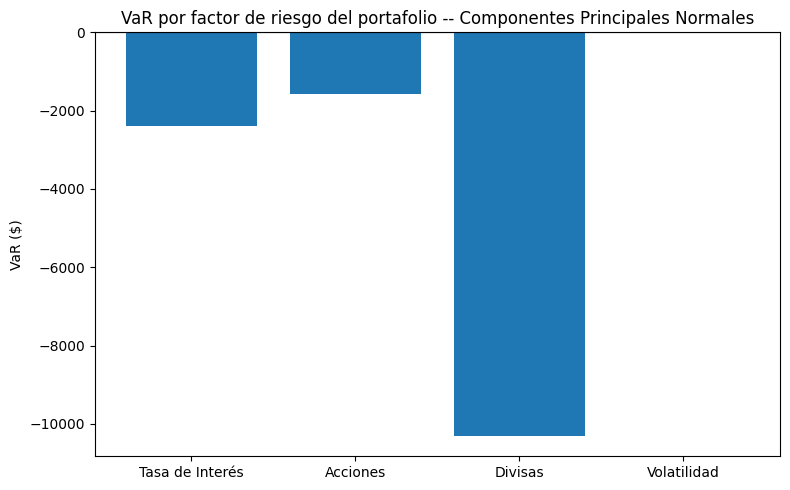

In [151]:
# @title 📋 Nivel factor de riesgo (portafolio) { display-mode: "both" }
def fila_factor(nombre, riesgo):
    return {
        "Factor de riesgo": nombre,
        "VaR": np.round(riesgo["VaR_total_q"], 2),
        "CVaR": np.round(riesgo["CVaR_total_q"], 2),
    }


resumen_factor = pd.DataFrame([
    fila_factor("Tasa de Inter\u00e9s", riesgo_bucket_ti),
    fila_factor("Acciones", riesgo_bucket_acciones),
    fila_factor("Divisas", riesgo_bucket_divisas),
    fila_factor("Volatilidad", riesgo_bucket_vol),
])

display(resumen_factor)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(resumen_factor["Factor de riesgo"], resumen_factor["VaR"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("VaR ($)")
ax.set_title(f"VaR por factor de riesgo del portafolio -- {info_mc['metodo']}")
plt.tight_layout()
plt.show()


In [152]:
# @title 📋 Nivel total (portafolio) { display-mode: "both" }
resumen_total = pd.DataFrame([{
    "Valor de mercado": np.round(V0T_port, 2),
    "VaR": np.round(riesgo_portafolio_total["VaR_total_q"], 2),
    "CVaR": np.round(riesgo_portafolio_total["CVaR_total_q"], 2),
    "M\u00e9todo de simulaci\u00f3n": info_mc["metodo"],
    "Simulaciones (Ns)": Ns,
}])

display(resumen_total)


,Valor de mercado,VaR,CVaR,Método de simulación,Simulaciones (Ns)
0,976585.37,-11910.22,-14171.94,Componentes Principales Normales,30000


 Cholesky Normal
	Factor de riesgo	VaR	CVaR
0	Tasa de Interés	-2785.27	-3279.65
1	Acciones	-11106.75	-13241.66
2	Divisas	-42570.08	-49889.31
3	Volatilidad	-0.60	-0.69
  976585.37	-46,171.93	-54,239.96	Cholesky Normal	30000

  Cholesky Empírica
Factor de riesgo	VaR	CVaR
0	Tasa de Interés	-2783.66	-3447.06
1	Acciones	-10932.96	-13159.92
2	Divisas	-39225.81	-57543.69
3	Volatilidad	-0.56	-0.77
  
  Valor de mercado	VaR	CVaR	Método de simulación	Simulaciones (Ns)
0	976585.37	-43,657.4	-60,828.15	Cholesky Empírico	30000

Componentes Principales Normales
Factor de riesgo	VaR	CVaR
0	Tasa de Interés	-2400.06	-2777.38
1	Acciones	-1556.36	-1890.65
2	Divisas	-10290.17	-12110.04
3	Volatilidad	-0.59	-0.69

	Valor de mercado	VaR	CVaR	Método de simulación	Simulaciones (Ns)
0	976585.37	-11,760.72	-13,936.92	Componentes Principales Normales	30000

Componentes Principales Empíricos

	Factor de riesgo	VaR	CVaR
0	Tasa de Interés	-2485.69	-3402.62
1	Acciones	-1741.09	-2576.38
2	Divisas	-10571.96	-13163.78
3	Volatilidad	-0.42	-0.71

	Valor de mercado	VaR	CVaR	Método de simulación	Simulaciones (Ns)
0	976585.37	-12,319.48	-16,047.17	Componentes Principales Empíricos	30000





# ✅ Glosario y para seguir practicando

### Glosario rápido
- **VaR (Valor en Riesgo):** la pérdida que, con cierto nivel de confianza `alpha`, no se espera superar en un día.
- **CVaR / Expected Shortfall:** la pérdida promedio en los escenarios que sí superan el VaR (más sensible a colas extremas).
- **Simulación Monte Carlo:** VaR/CVaR calculado revaluando la cartera bajo escenarios **sintéticos**, generados a partir de un modelo ajustado al histórico (en vez de escenarios realmente observados, como en la simulación histórica).
- **Descomposición de Cholesky:** forma de "inyectar" la correlación histórica a variables simuladas independientes, multiplicándolas por una matriz triangular $L$ tal que $LL^\top=\Sigma$.
- **Componentes Principales (PCA):** direcciones (eigenvectores) no correlacionadas que concentran la mayor parte de la varianza de los factores de riesgo; simular solo las primeras `k` (las que explican una fracción `eta` de la varianza) reduce la dimensión del problema.
- **Factor de riesgo:** cada curva/precio de mercado del que depende la valuación (curva de descuento, tasa spot, volatilidad, tipo de cambio, precio de una acción, etc.).
- **Nivel contrato / instrumento / factor de riesgo / total:** las cuatro formas de agregar el riesgo — por posición individual, por tipo de instrumento, por tipo de factor de mercado (sin importar el instrumento), y para toda la cartera.

### 🧪 Ejercicios sugeridos
1. Cambia `metodo_simulacion` entre "Cholesky" y "Componentes Principales", y compara el VaR total y el tiempo de ejecución.
2. Baja `varianza_explicada` (eta) a 0.5: ¿con cuántos componentes principales se queda el modelo? ¿Cómo cambia el VaR frente a eta=0.85 o 0.99?
3. Cambia `distribucion` a "Empírica" y compara contra "Normal" -- ¿en qué instrumentos cambia más el CVaR (la cola)?
4. Sube `numero_simulaciones` (Ns) y observa cómo se estabilizan los cocientes de varianza de la celda "Generación de escenarios" -- cada vez más cerca de 1.0.
5. Compara este cuaderno contra `SH_Integracion_python.ipynb` (simulación histórica) con los mismos parámetros de cartera: ¿el VaR Monte Carlo es mayor o menor que el histórico? ¿Por qué podrían diferir?
